<a href="https://colab.research.google.com/github/at13lemmewrite/PGDM-/blob/main/lecture_9_%26_10_%26_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Zepto_Orders_Data (1).xlsx", sheet_name="Orders")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 1200 | Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


In [2]:
df.describe().round(1)

,Order_Date,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
count,1200,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2026-08-20 19:57:36,1.6,4.9,422.9,15.5,13.0,4.5
min,2026-07-01 00:00:00,0.3,1.0,50.0,0.0,4.0,2.8
25%,2026-07-31 00:00:00,0.8,3.0,230.0,8.0,9.0,4.2
50%,2026-08-23 00:00:00,1.3,5.0,350.0,14.0,12.0,4.6
75%,2026-09-12 00:00:00,2.2,6.0,560.0,22.0,16.0,4.9
max,2026-09-30 00:00:00,4.0,11.0,2230.0,46.0,31.0,5.0
std,NaN,1.0,2.0,270.3,9.9,4.9,0.4


In [3]:
# Total no. of states
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


In [4]:
df["Week"]       = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"]    = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10      # True if we kept the

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


In [5]:
import matplotlib.pyplot as plt

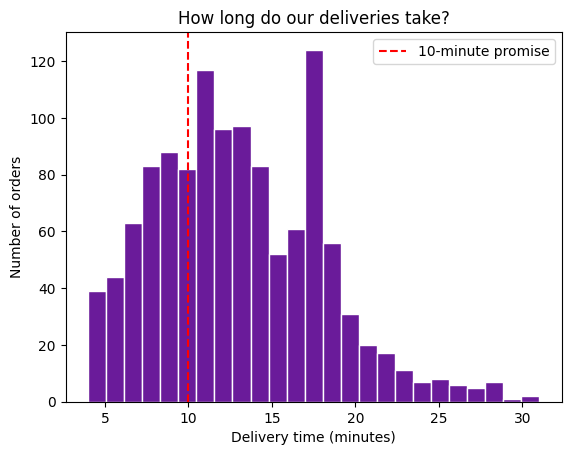

In [6]:
# Create histogram of delivery times
plt.hist(df["Delivery_Time_Min"], bins=25, color="#6A1B9A", edgecolor="white")

# Add vertical threshold line for 10-minute promise
plt.axvline(10, color="red", linestyle="--", label="10-minute promise")

# Chart labels and title
plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

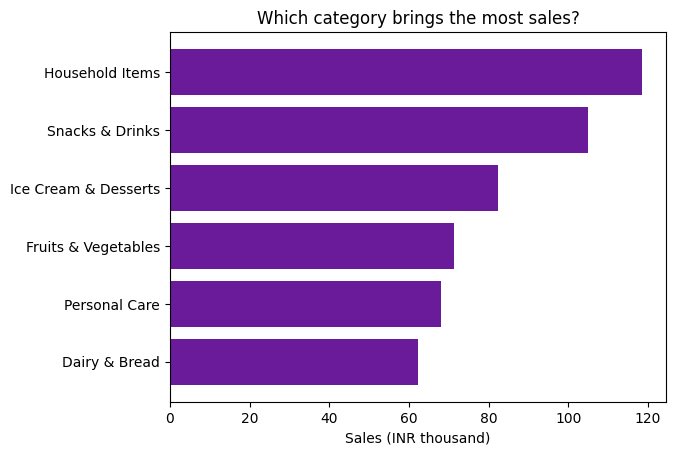

In [7]:
# Group by Category and get total sales, sorted from lowest to highest for horizontal bar chart
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

# Create horizontal bar chart
plt.barh(category_sales.index, category_sales.values / 1000, color="#6A1B9A")
plt.title("Which category brings the most sales?")
plt.xlabel("Sales (INR thousand)")
plt.show()

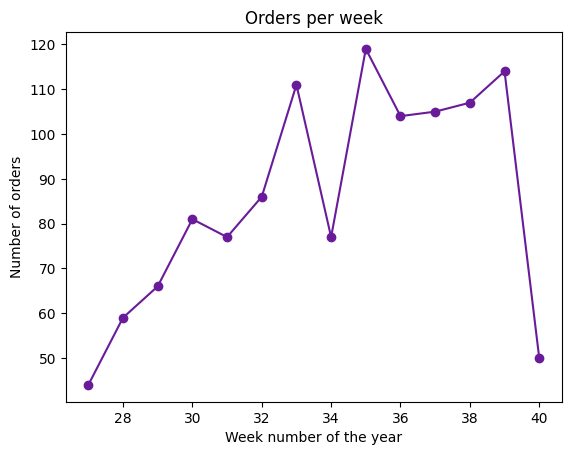

In [8]:
# Group by week and count the number of orders
weekly_orders = df.groupby("Week")["Order_ID"].count()

# Create a clean line plot
plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

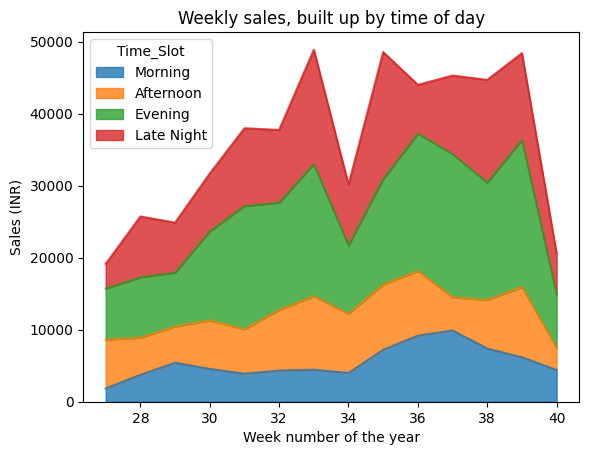

In [9]:
# Pivot the data to get weekly sales summed by Time Slot
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

# Create an area plot to show built-up sales
week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

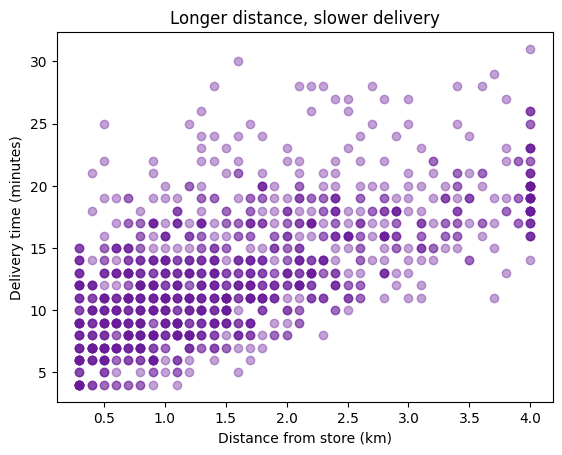

In [10]:
# Create a scatter plot of distance vs delivery time
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")

# Configure chart title and labels on separate lines
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

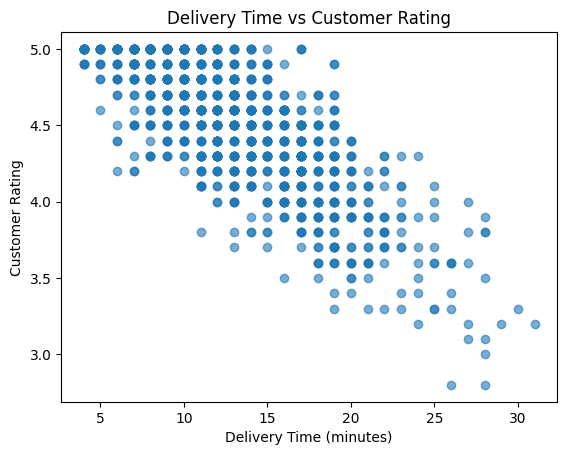

In [11]:
# Create a scatter plot of delivery time vs customer rating
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.6)

# Configure chart title and labels
plt.title("Delivery Time vs Customer Rating")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Customer Rating")

# Display the scatter plot
plt.show()

how much does a raining hurt delievery time and rating in each state

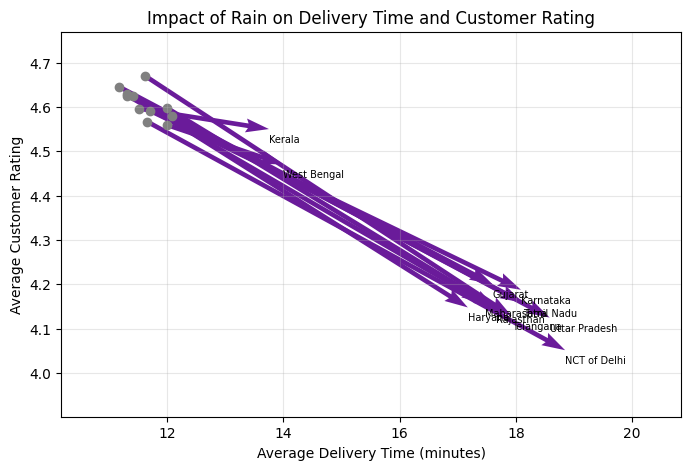

In [12]:
means = df.groupby(["State", "Weather"])[
    ["Delivery_Time_Min", "Customer_Rating"]
].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain = means[means["Weather"] == "Rain"].set_index("State")

# Starting points: Clear weather
x = clear["Delivery_Time_Min"]
y = clear["Customer_Rating"]

# Changes during rainy weather
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]
dy = rain["Customer_Rating"] - clear["Customer_Rating"]
# Create the arrow chart
plt.figure(figsize=(8, 5))

plt.quiver(
    x, y, dx, dy,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="#6A1B9A"
)

plt.scatter(x, y, color="grey")

# Add state names at the end of each arrow
for name in clear.index:
    plt.text(
        x[name] + dx[name],
        y[name] + dy[name] - 0.03,
        name,
        fontsize=7
    )

# Configure chart limits
plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)

# Add title and axis labels
plt.title("Impact of Rain on Delivery Time and Customer Rating")
plt.xlabel("Average Delivery Time (minutes)")
plt.ylabel("Average Customer Rating")

plt.grid(alpha=0.3)
plt.show()

In [13]:
# Developing, Mesh Grid
import numpy as np
# developing mesh grid
# A tiny example first
distance = np.array([1, 2, 3])
basket = np.array([5, 10])

D, B = np.meshgrid(distance, basket)
print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


In [14]:
import numpy as np

dist_values = np.linspace(0.3, 4, 40)  # 40 distances from 0.3 to 4 km

basket_values = np.linspace(1, 12, 40)  # 40 basket sizes from 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


In [15]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create a simple regression model
formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

# Display the impact of each variable
print("Each extra km adds about",
      round(formula.coef_[0], 2), "minutes")

print("Each extra item adds about",
      round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.11 minutes
Each extra item adds about 0.31 minutes


In [16]:
# Fill every what-if case with the expected delivery time

cases = pd.DataFrame({
    "Distance_KM": D.ravel(),
    "Basket_Size": B.ravel()
})

T = formula.predict(cases).reshape(D.shape)

print("Predicted delivery time table shape:", T.shape)


Predicted delivery time table shape: (40, 40)


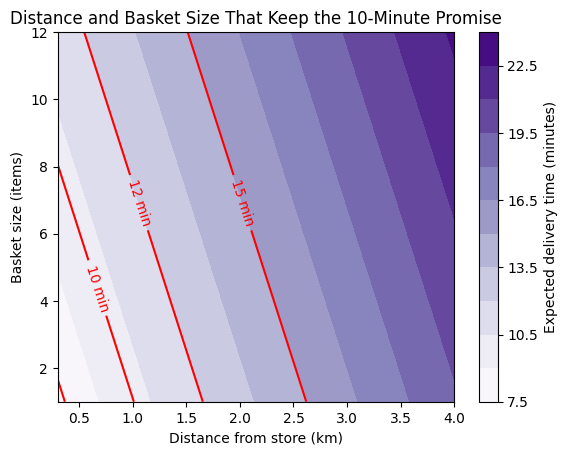

In [17]:
# Create contour plot
plt.contourf(D, B, T, levels=10, cmap="Purples")

# Add colour bar
plt.colorbar(label="Expected delivery time (minutes)")

# Add contour lines
lines = plt.contour(
    D, B, T,
    levels=[8, 10, 12, 15],
    colors="red"
)

# Add labels to contour lines
plt.clabel(lines, fmt="%d min")

# Add title and axis labels
plt.title("Distance and Basket Size That Keep the 10-Minute Promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")

plt.show()

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Running total of sales, week by week, for each state
running = df.pivot_table(
    index="Week",
    columns="State",
    values="Order_Value",
    aggfunc="sum"
).fillna(0).cumsum()

# Sort states from smallest to largest
running = running[running.iloc[-1].sort_values().index]

# Create figure
fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()

    ax.barh(
        running.columns,
        running.iloc[i] / 1000,
        color="#6A1B9A"
    )

    ax.set_xlim(0, running.values.max() / 1000 * 1.1)

    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

    ax.grid(axis="x", alpha=0.3)

# Create animation
ani = FuncAnimation(
    fig,
    draw,
    frames=len(running),
    interval=800,
    repeat=True
)

# Display animation in Google Colab
plt.close(fig)
HTML(ani.to_jshtml())

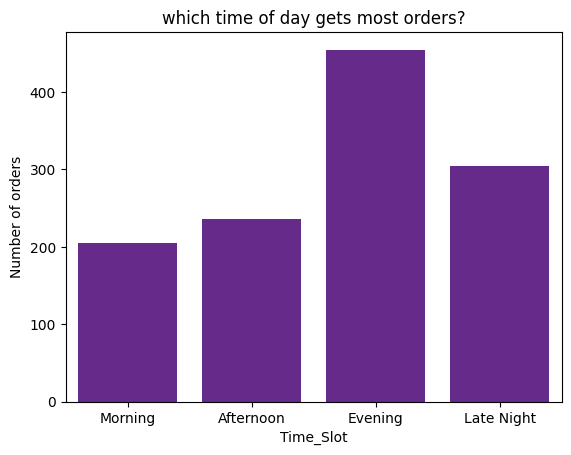

In [19]:
#countplot by seaborn
import seaborn as sns
sns.countplot(data=df, x="Time_Slot", order=slot_order, color="#6A1B9A")
plt.title("which time of day gets most orders?")
plt.ylabel("Number of orders")
plt.show()

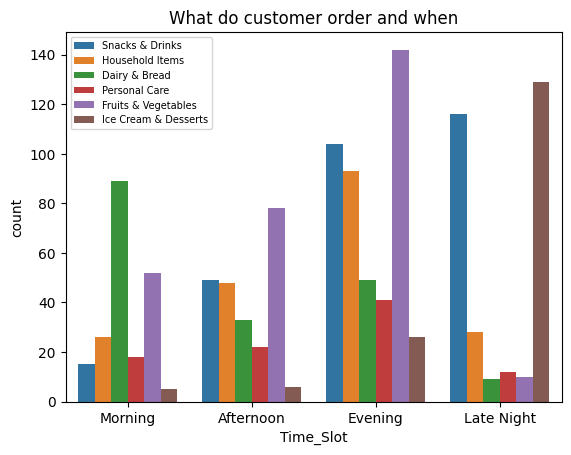

In [20]:
sns.countplot(data=df, x="Time_Slot", order=slot_order, hue="Category")
plt.title("What do customer order and when")
plt.legend(fontsize=7)
plt.show()

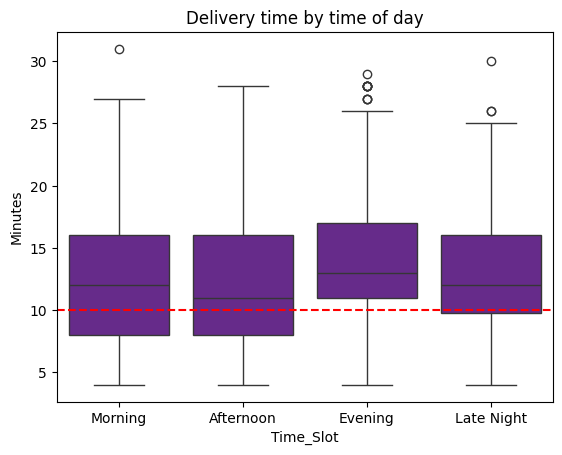

In [21]:
#Box plot(Seaborn)
sns.boxplot(data=df, x="Time_Slot", y="Delivery_Time_Min", order=slot_order, color="#6A1B9A")
plt.axhline(10, color="red", linestyle="--")
plt.title("Delivery time by time of day")
plt.ylabel("Minutes")
plt.show()

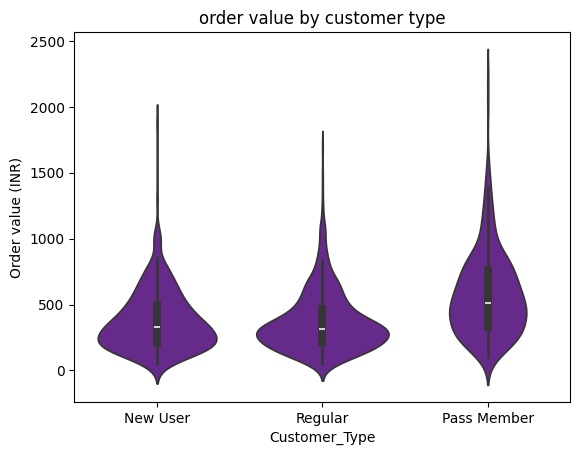

In [22]:
sns.violinplot(data=df, x="Customer_Type", y="Order_Value", order=type_order, color="#6A1B9A")
plt.title("order value by customer type")
plt.ylabel("Order value (INR)")
plt.show()

a low rating caused by many others or only by few - split plot by seaborn

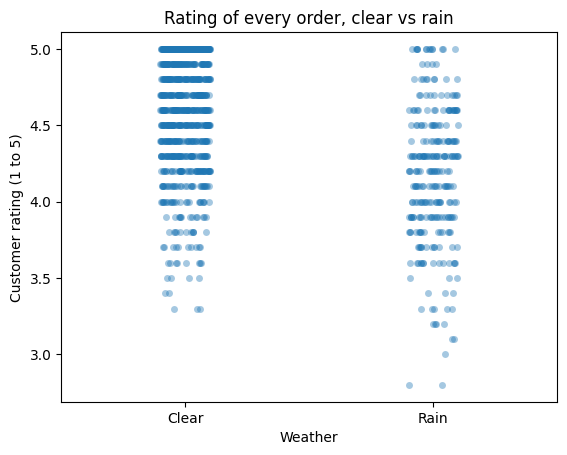

In [23]:
sns.stripplot(data=df, x="Weather", y="Customer_Rating", jitter=True, alpha=0.4)
plt.title("Rating of every order, clear vs rain")
plt.ylabel("Customer rating (1 to 5)")
plt.show()